# 01 · Exploración del dataset de dengue

Este notebook documenta la exploración inicial del dataset utilizado en el proyecto. El objetivo es identificar la variable objetivo, revisar la calidad de los datos y justificar las variables que se utilizarán en los modelos.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.modeling import (
    INPUT_FEATURE_COLUMNS, MODEL_FEATURE_COLUMNS, TARGET_COLUMN,
    engineer_features, load_dataset, remove_constant_columns
)

DATASET_PATH = PROJECT_ROOT / 'MASTER_CHART_F1000Research.xlsx'
df = load_dataset(DATASET_PATH)
df.head()

,GROUPS: DENGUE FEVER OR COMPLICATED DENGUE,AGE,GENDER,DURATION OF FEVER,HEADACHE,MYALGIA,ABDOMINAL PAIN,RASH,VOMITING,BREATHLESSNESS,...,LOWEST WBC,HIGHEST WBC,PLATELET COUNT,ALT,CREATININE,FERRITIN,IV FLUIDS,ANTIBIOTICS,ANTIPYRETICS,STEROIDS
0,2,2,1,3,2,1,2,2,1,2,...,3400,5100,30000,53.0,0.62,4167.0,1,1,2,1
1,2,2,1,4,2,1,2,2,2,2,...,3000,5300,43000,21.0,0.43,108.0,1,2,2,2
2,1,1,2,3,2,1,2,2,2,2,...,2300,2600,129000,12.0,0.34,212.0,1,1,1,2
3,1,2,2,5,2,1,2,2,2,2,...,1500,4800,70000,171.0,0.80,1429.0,1,1,1,1
4,1,2,2,3,2,1,2,2,2,2,...,8600,9100,184000,45.0,0.44,NaN,1,2,1,2


## Dimensiones y tipos de datos

In [2]:
print(f'Filas: {df.shape[0]}')
print(f'Columnas: {df.shape[1]}')
df.info()

Filas: 303
Columnas: 25
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 25 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   GROUPS: DENGUE FEVER OR COMPLICATED DENGUE  303 non-null    int64  
 1   AGE                                         303 non-null    int64  
 2   GENDER                                      303 non-null    int64  
 3   DURATION OF FEVER                           303 non-null    int64  
 4   HEADACHE                                    303 non-null    int64  
 5   MYALGIA                                     303 non-null    int64  
 6   ABDOMINAL PAIN                              303 non-null    int64  
 7   RASH                                        303 non-null    int64  
 8   VOMITING                                    303 non-null    int64  
 9   BREATHLESSNESS                              303 non-null    int64  
 10  B

In [3]:
missing = df.isna().sum().sort_values(ascending=False)
missing[missing > 0].to_frame('valores_faltantes')

,valores_faltantes
FERRITIN,112
ALT,1
CREATININE,1


## Variable objetivo

El archivo codifica `1` como dengue no complicado y `2` como dengue complicado. Para entrenar los clasificadores se transformará a `0` y `1`, donde `1` será la clase positiva: dengue complicado.

,pacientes
GROUPS: DENGUE FEVER OR COMPLICATED DENGUE,
No complicado,240
Complicado,63


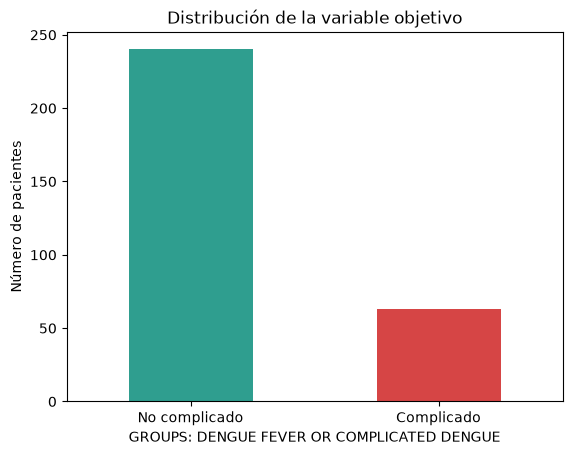

In [4]:
target_counts = df[TARGET_COLUMN].value_counts().sort_index()
display(target_counts.rename(index={1: 'No complicado', 2: 'Complicado'}).to_frame('pacientes'))

ax = target_counts.rename(index={1: 'No complicado', 2: 'Complicado'}).plot(kind='bar', color=['#2f9e8f', '#d64545'])
ax.set_title('Distribución de la variable objetivo')
ax.set_ylabel('Número de pacientes')
plt.xticks(rotation=0)
plt.show()

## Variables seleccionadas

Se utilizan las variables base `DURATION OF FEVER`, `PCV`, `PLATELET COUNT`, `HIGHEST WBC`, `ALT` y `BP AT ADMISSION`. A partir de ellas se crean variables binarias con los puntos de corte del artículo y una razón plaquetas/PCV. No se utiliza ferritina porque presenta muchos valores faltantes y tampoco se incluyen tratamientos, ya que pueden contener información posterior al ingreso.

In [5]:
# 1) Eliminación de columnas constantes entre los predictores
predictors = df.drop(columns=[TARGET_COLUMN])
predictors_clean, constant_columns = remove_constant_columns(predictors)
print('Columnas constantes eliminadas:', constant_columns if constant_columns else 'Ninguna')

# 2) Conversión explícita a valores numéricos y de códigos 1/2 a indicadores 0/1
numeric_inputs = predictors_clean.copy()
for column in INPUT_FEATURE_COLUMNS:
    numeric_inputs[column] = pd.to_numeric(numeric_inputs[column], errors='coerce')
numeric_inputs['HYPOTENSION_TEXT'] = numeric_inputs['BP AT ADMISSION'].map({1: 'Sí', 2: 'No'})
numeric_inputs['HYPOTENSION'] = numeric_inputs['BP AT ADMISSION'].map({1: 1, 2: 0})
display(numeric_inputs[['BP AT ADMISSION', 'HYPOTENSION_TEXT', 'HYPOTENSION']].head())

# 3) Creación de nuevas variables para el modelamiento
engineered = engineer_features(df)
engineered.describe().T

Columnas constantes eliminadas: Ninguna


,BP AT ADMISSION,HYPOTENSION_TEXT,HYPOTENSION
0,2,No,0
1,1,Sí,1
2,1,Sí,1
3,1,Sí,1
4,1,Sí,1


,count,mean,std,min,25%,50%,75%,max
DURATION OF FEVER,303.0,3.976898,2.035153,1.000000,2.000000,4.000000,5.000000,10.000000
PCV,303.0,40.108911,4.035121,28.500000,37.800000,39.900000,42.350000,54.600000
PLATELET COUNT,303.0,102170.627063,66342.869896,11000.000000,55000.000000,90000.000000,130000.000000,479000.000000
HIGHEST WBC,303.0,5724.191419,3142.266433,1500.000000,3600.000000,5100.000000,6950.000000,24100.000000
ALT,302.0,66.925497,139.528687,5.000000,16.250000,26.000000,52.750000,1481.000000
PCV_HIGH,303.0,0.277228,0.448370,0.000000,0.000000,0.000000,1.000000,1.000000
PLATELETS_LOW,303.0,0.399340,0.490573,0.000000,0.000000,0.000000,1.000000,1.000000
WBC_HIGH,303.0,0.250825,0.434205,0.000000,0.000000,0.000000,0.500000,1.000000
ALT_ELEVATED,302.0,0.225166,0.418385,0.000000,0.000000,0.000000,0.000000,1.000000
HYPOTENSION,303.0,0.874587,0.331734,0.000000,1.000000,1.000000,1.000000,1.000000


In [6]:
df.groupby(TARGET_COLUMN)[INPUT_FEATURE_COLUMNS].mean().T.rename(columns={1: 'No complicado', 2: 'Complicado'})

GROUPS: DENGUE FEVER OR COMPLICATED DENGUE,No complicado,Complicado
DURATION OF FEVER,3.816667,4.587302
PCV,39.680417,41.741270
PLATELET COUNT,110773.750000,69396.825397
HIGHEST WBC,5411.125000,6916.825397
ALT,40.364017,167.690476
BP AT ADMISSION,1.037500,1.460317


### Conclusión

El dataset contiene 303 pacientes y presenta un desbalance de clases. Por este motivo, la regresión logística se entrenará con `class_weight='balanced'` y la evaluación incluirá sensibilidad, especificidad, F1 y ROC-AUC, además de accuracy. Los valores faltantes serán imputados con la mediana dentro del pipeline de cada modelo.